Order of Events
1. Get coordinates of environment (from Vision)
2. Compute visibility graph and path (from Global Nav)
3. Start following path
4. Continuously correct route with Kalman filter (from Kalman)
5. Add extra obstacle in path
6. Avoid obstacle (from Local Nav)
7. Reach goal

In [1]:
import numpy as np 
import matplotlib.pyplot as plt
from tdmclient import ClientAsync, aw
import math
from VisibilityGraph import *
from kalman_filter import *

In [3]:
client = ClientAsync()
node = aw(client.wait_for_node())
await node.lock()

Node eeecc8f0-055d-414f-a168-42c3ba3a5cd9

In [4]:
# Global Nav Variables as standin for input from Vision

ob1 = [(176, 206), (215, 217), (194, 294), (155, 283)]
ob2 = [(522, 440), (562, 440), (562, 520), (522, 520)]
ob3 = [(870, 267), (909, 256), (930, 333), (891, 344)]

start = (1, 1)
goal = (1000, 700)
raw_obstacles = (ob1, ob2, ob3)

5
[0, 5, 9, 11, 1] [array([1000.,  700.]), array([810.57377468, 486.17108677]), array([677., 325.]), array([355.94549682, 137.26709127]), array([1., 1.])]


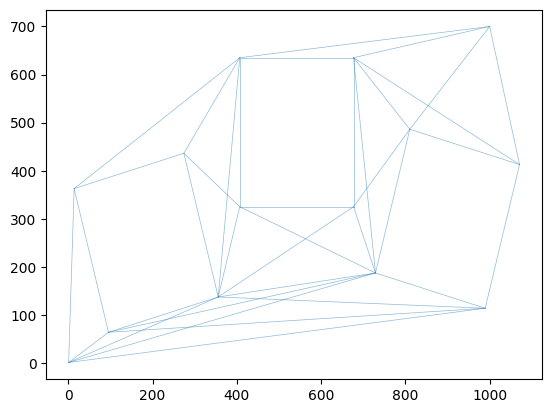

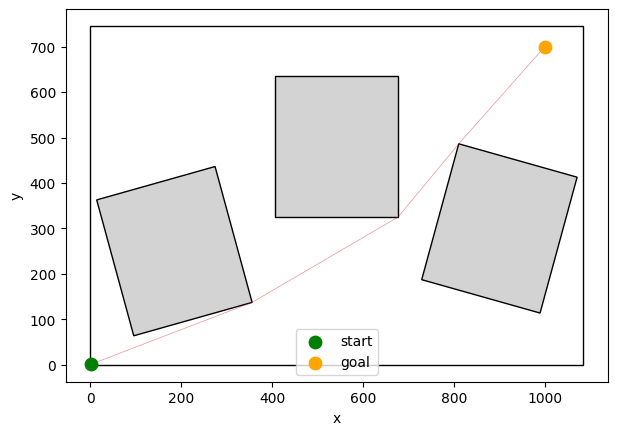

In [ ]:
path, coords = run_global_nav(start, goal, raw_obstacles)
print(path, coords)

def compute_heading(a, b, prev_heading):
    distance = np.linalg.norm(a - b, ord=2)
    
    dx = b[0] - a[0]
    dy = b[1] - a[1]
    heading = math.atan(dy/dx) - prev_heading
    prev_heading = math.atan(dy/dx)

    return distance, heading, prev_heading

In [6]:
SPEED_TO_MM_S = 0.335   
WHEEL_BASE = 95.0

async def set_speed(left, right):
    await node.set_variables({
        "motor.left.target": [int(left)],
        "motor.right.target": [int(right)]
    })
    
async def forward(v, d): # [mm/s, mm]
    T = d/v
    thymio_v = v/SPEED_TO_MM_S
    
    try:
        await set_speed(thymio_v, thymio_v)
        await client.sleep(T)          
    finally:
        await set_speed(0, 0)
        
async def turn(v, theta): # [rad/s, rad]

    arc = abs(theta) * WHEEL_BASE / 2 
    T = arc / v                          
    thymio_v =  abs(v) / SPEED_TO_MM_S         
    direction = 1 if theta > 0 else -1
    try:
        await set_speed(-direction * thymio_v, direction * thymio_v)
        await client.sleep(T)
    finally:
        await set_speed(0, 0)

In [28]:
v = 100
prev_heading = 0

for i in range(len(path)-1):
    distance, heading, prev_heading = compute_heading(coords[i], coords[i+1], prev_heading)
    print(distance, heading)
    await turn(v, heading)
    await forward(v, distance)




TypeError: math.atan() takes exactly one argument (2 given)

In [ ]:
await forward(100, 10)

In [26]:
await turn(100, np.pi)